# Étape 5 — Segmentation par K-Means

Ce notebook applique **uniquement K-Means** aux six variables de dépenses déjà préparées par la stratégie `log1p + StandardScaler`. `Channel`, `Region` et `customer_index` restent exclus des distances.

L'objectif est de rechercher un nombre de groupes raisonnable, d'entraîner un modèle reproductible et de décrire les profils obtenus sur les dépenses originales. La PCA est utilisée seulement comme projection visuelle.

## 1. Principe pédagogique

K-Means partitionne les observations en $K$ groupes en cherchant des centroïdes représentatifs. Pour une observation $x_i$ et un centroïde $\mu_k$, la distance euclidienne est $d(x_i,\mu_k)=\sqrt{\sum_j(x_{ij}-\mu_{kj})^2}$.

À chaque itération, l'algorithme (1) affecte chaque client au centroïde le plus proche, puis (2) recalcule chaque centroïde par la moyenne des clients affectés : $\mu_k=\frac{1}{|C_k|}\sum_{x_i\in C_k}x_i$. Il minimise l'inertie intra-classe $J=\sum_{k=1}^{K}\sum_{x_i\in C_k}||x_i-\mu_k||^2$.

K-Means++ choisit les centres initiaux de façon plus informée. La convergence est atteinte lorsque les affectations ou les centres ne changent pratiquement plus. Les limites principales sont la sensibilité à l'échelle et aux valeurs extrêmes, l'hypothèse de groupes plutôt compacts et la nécessité de choisir $K$.

In [1]:
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

sns.set_theme(style='whitegrid', context='notebook')
project_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
prepared_path = project_root / 'data' / 'processed' / 'customers_log_standard_scaled.csv'
raw_path = project_root / 'data' / 'raw' / 'Wholesale customers data.csv'
figures_dir = project_root / 'results' / 'figures'
tables_dir = project_root / 'results' / 'tables'
models_dir = project_root / 'models'
for directory in (figures_dir, tables_dir, models_dir):
    directory.mkdir(parents=True, exist_ok=True)
FEATURES = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
EXPECTED_ROWS = 440
X = pd.read_csv(prepared_path, index_col='customer_index')
print(f'Données préparées : {X.shape[0]} lignes et {X.shape[1]} variables')
print('Index :', X.index.name, '| Variables :', list(X.columns))

Données préparées : 440 lignes et 6 variables
Index : customer_index | Variables : ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']


## 2. Chargement et contrôles

La colonne `customer_index` est l'identifiant de ligne. Elle sert à réaligner les résultats, mais elle ne représente pas un comportement de dépense et ne doit donc jamais entrer dans les distances.

In [2]:
assert X.shape == (EXPECTED_ROWS, 6)
assert list(X.columns) == FEATURES
assert X.index.name == 'customer_index' and X.index.is_unique
assert not X.isna().any().any()
assert np.isfinite(X.to_numpy()).all()
display(X.head())
display(X.describe().round(3))
print('Contrôles de chargement : OK — aucune valeur NaN ou infinie.')

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
customer_index,,,,,,
0,0.486184,0.976299,0.440155,-1.509250,0.644143,0.408966
1,0.087889,0.990956,0.652171,0.134052,0.766043,0.627926
2,0.016356,0.891151,0.454687,0.376899,0.804405,1.776833
3,0.517477,-0.957973,-0.084792,1.141574,-0.328712,0.633133
4,0.880631,0.439662,0.395847,0.757322,0.404939,1.456588


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000,440.000,440.000,440.000,440.000,440.000
mean,0.000,-0.000,-0.000,0.000,-0.000,-0.000
std,1.001,1.001,1.001,1.001,1.001,1.001
min,-5.001,-3.795,-6.355,-3.159,-3.166,-4.089
25%,-0.466,-0.728,-0.691,-0.541,-0.726,-0.508
50%,0.215,0.069,0.023,0.022,-0.050,0.157
75%,0.684,0.703,0.749,0.682,0.868,0.647
max,1.971,2.857,2.698,2.900,2.240,3.177


Contrôles de chargement : OK — aucune valeur NaN ou infinie.


## 3. Recherche de K entre 2 et 10

L'inertie diminue mécaniquement quand $K$ augmente : elle aide à repérer un compromis, mais ne suffit pas seule. Le score de silhouette compare la cohésion d'un groupe à sa séparation des autres groupes ; il est calculé ici sur les six variables préparées. Les effectifs permettent d'éviter une solution difficile à interpréter avec un groupe minuscule.

In [3]:
search_rows = []
models_by_k = {}
for k in range(2, 11):
    model = KMeans(n_clusters=k, init='k-means++', n_init=20, random_state=42)
    model.fit(X)
    sizes = pd.Series(model.labels_).value_counts().sort_index()
    models_by_k[k] = model
    search_rows.append({
        'K': k,
        'Inertie': model.inertia_,
        'Silhouette': silhouette_score(X, model.labels_),
        'Iterations': model.n_iter_,
        'Taille_min': int(sizes.min()),
        'Taille_max': int(sizes.max()),
        'Tailles_clusters': ', '.join(str(int(v)) for v in sizes)
    })
k_results = pd.DataFrame(search_rows)
display(k_results.round({'Inertie': 2, 'Silhouette': 4}))
k_results.to_csv(tables_dir / 'kmeans_search_metrics.csv', index=False)

,K,Inertie,Silhouette,Iterations,Taille_min,Taille_max,Tailles_clusters
0,2,1844.06,0.2903,13,188,252,"252, 188"
1,3,1553.41,0.2583,7,83,212,"145, 212, 83"
2,4,1386.86,0.1885,24,61,132,"61, 129, 132, 118"
3,5,1266.15,0.1916,26,54,100,"90, 96, 54, 100, 100"
4,6,1174.54,0.1953,19,15,110,"91, 85, 110, 15, 56, 83"
5,7,1086.36,0.1958,20,20,118,"20, 41, 48, 89, 84, 118, 40"
6,8,1024.05,0.1915,32,12,107,"78, 28, 107, 46, 12, 21, 80, 68"
7,9,973.14,0.1965,12,11,101,"19, 101, 84, 47, 64, 42, 28, 11, 44"
8,10,932.00,0.1905,13,11,114,"18, 114, 16, 45, 40, 31, 42, 71, 11, 52"


## 4. Courbes Elbow et silhouette

Les deux figures sont enregistrées en haute résolution. Une baisse régulière de l'inertie ne constitue pas automatiquement un coude net ; la décision sera donc reliée aussi à la silhouette, aux tailles et à l'interprétabilité.

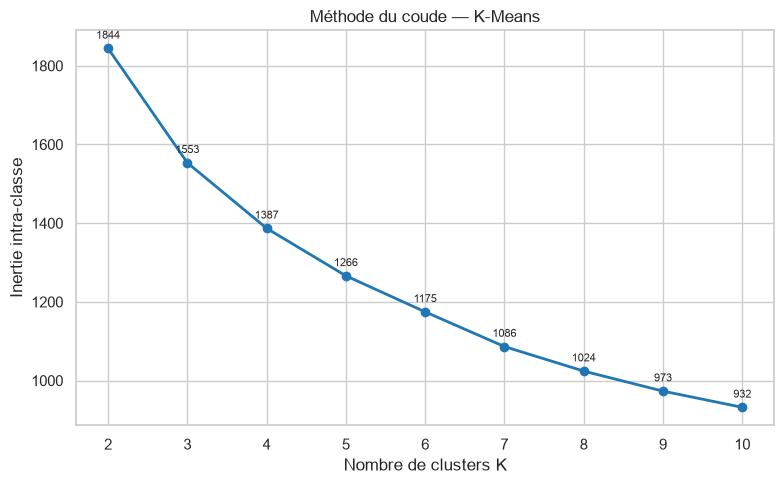

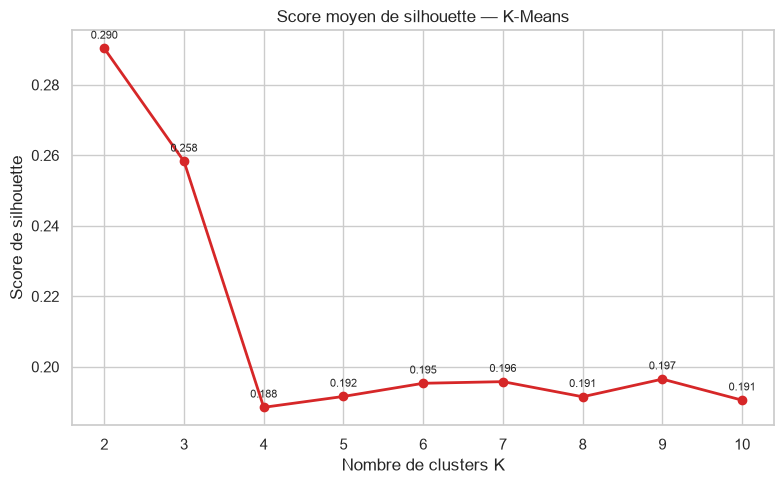

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(k_results['K'], k_results['Inertie'], marker='o', linewidth=2, color='#1f77b4')
for _, row in k_results.iterrows(): ax.annotate(f"{row['Inertie']:.0f}", (row['K'], row['Inertie']), textcoords='offset points', xytext=(0, 7), ha='center', fontsize=8)
ax.set(title='Méthode du coude — K-Means', xlabel='Nombre de clusters K', ylabel='Inertie intra-classe')
fig.tight_layout(); fig.savefig(figures_dir / '09_kmeans_elbow.png', dpi=180, bbox_inches='tight'); plt.show(); plt.close(fig)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(k_results['K'], k_results['Silhouette'], marker='o', linewidth=2, color='#d62728')
for _, row in k_results.iterrows(): ax.annotate(f"{row['Silhouette']:.3f}", (row['K'], row['Silhouette']), textcoords='offset points', xytext=(0, 7), ha='center', fontsize=8)
ax.set(title='Score moyen de silhouette — K-Means', xlabel='Nombre de clusters K', ylabel='Score de silhouette')
fig.tight_layout(); fig.savefig(figures_dir / '10_kmeans_silhouette.png', dpi=180, bbox_inches='tight'); plt.show(); plt.close(fig)

## 5. Choix provisoire de K

Pour rendre la règle explicite, nous retenons le meilleur score de silhouette parmi les solutions dont le plus petit cluster contient au moins 5 % des clients (22 clients). Cette règle ne remplace pas l'interprétation métier : elle évite simplement de sélectionner un groupe très petit sans justification. Les alternatives proches restent documentées.

In [5]:
eligible = k_results[k_results['Taille_min'] >= int(np.ceil(0.05 * EXPECTED_ROWS))]
selected_k = int(eligible.loc[eligible['Silhouette'].idxmax(), 'K'])
best_silhouette_k = int(k_results.loc[k_results['Silhouette'].idxmax(), 'K'])
print(f'K provisoire retenu : {selected_k}')
selected_silhouette = float(eligible.loc[eligible['K'] == selected_k, 'Silhouette'].iloc[0])
print(f'Silhouette correspondante : {selected_silhouette:.4f}')
print(f'Meilleure silhouette sans contrainte de taille : K={best_silhouette_k}')
print('Justification : compromis entre silhouette, effectifs non minuscules et interprétabilité ; aucun K=3 n’est imposé.')
display(k_results.sort_values('Silhouette', ascending=False).head(3).round({'Inertie': 2, 'Silhouette': 4}))

K provisoire retenu : 2
Silhouette correspondante : 0.2903
Meilleure silhouette sans contrainte de taille : K=2
Justification : compromis entre silhouette, effectifs non minuscules et interprétabilité ; aucun K=3 n’est imposé.


,K,Inertie,Silhouette,Iterations,Taille_min,Taille_max,Tailles_clusters
0,2,1844.06,0.2903,13,188,252,"252, 188"
1,3,1553.41,0.2583,7,83,212,"145, 212, 83"
7,9,973.14,0.1965,12,11,101,"19, 101, 84, 47, 64, 42, 28, 11, 44"


## 6. Entraînement final et sauvegarde

Le modèle final utilise toujours les six variables préparées. Les labels sont sauvegardés avec `customer_index` afin de garantir l'alignement avec le fichier original.

In [6]:
final_model = KMeans(n_clusters=selected_k, init='k-means++', n_init=20, random_state=42)
final_model.fit(X)
labels = pd.Series(final_model.labels_, index=X.index, name='cluster')
counts = labels.value_counts().sort_index()
final_summary = pd.DataFrame({'Cluster': counts.index, 'Nombre_clients': counts.values, 'Pourcentage': (counts.values / len(labels) * 100).round(2)})
print(f'Inertie finale : {final_model.inertia_:.4f}')
print(f'Silhouette finale : {silhouette_score(X, labels):.4f}')
display(final_summary)
labels.to_frame().to_csv(tables_dir / 'kmeans_client_labels.csv', index=True, index_label='customer_index')
pd.DataFrame(final_model.cluster_centers_, columns=FEATURES, index=range(selected_k)).to_csv(tables_dir / 'kmeans_centroids_prepared.csv', index_label='cluster')
with open(models_dir / 'kmeans_final.pkl', 'wb') as handle: pickle.dump({'model': final_model, 'features': FEATURES, 'selected_k': selected_k}, handle)

Inertie finale : 1844.0641
Silhouette finale : 0.2903


,Cluster,Nombre_clients,Pourcentage
0,0,252,57.27
1,1,188,42.73


## 7. Profils sur les dépenses originales

Pour l'interprétation, les labels sont joints au CSV original, sans utiliser `Channel` ou `Region` pour entraîner le modèle. Les moyennes et médianes ci-dessous restent donc dans l'échelle initiale des dépenses.

In [7]:
raw = pd.read_csv(raw_path)
assert raw.shape[0] == X.shape[0] and list(raw[FEATURES].columns) == FEATURES
analysis = raw.copy()
analysis['cluster'] = labels.to_numpy()
means = analysis.groupby('cluster')[FEATURES].mean()
medians = analysis.groupby('cluster')[FEATURES].median()
profiles = means.copy()
profiles.insert(0, 'Nombre_clients', counts)
profiles.insert(1, 'Pourcentage', (counts / len(labels) * 100).round(2))
display(profiles.round(2))
display(medians.round(2).style.format('{:.2f}'))
profiles.to_csv(tables_dir / 'kmeans_cluster_profiles_original.csv', index_label='cluster')
channel_region = pd.crosstab(analysis['cluster'], [analysis['Channel'], analysis['Region']])
channel_region.to_csv(tables_dir / 'kmeans_cluster_channel_region.csv', index_label='cluster')
display(channel_region)

,Nombre_clients,Pourcentage,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
cluster,,,,,,,,
0,252,57.27,13973.13,2401.75,2918.71,3705.67,491.94,1038.04
1,188,42.73,9355.87,10346.36,14697.06,2222.45,6084.51,2177.43


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
cluster,,,,,,
0,10347.50,1871.00,2406.00,2225.00,327.50,749.50
1,5406.50,7690.50,11527.00,1061.50,4495.00,1388.50


Channel   1            2         
Region    1   2    3   1   2    3
cluster                          
0        46  26  172   2   2    4
1        13   2   39  16  17  101

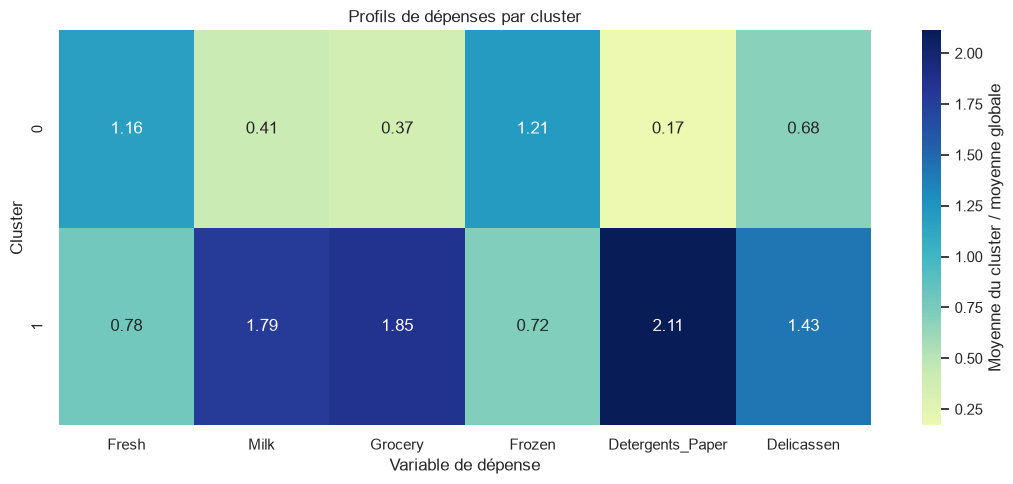

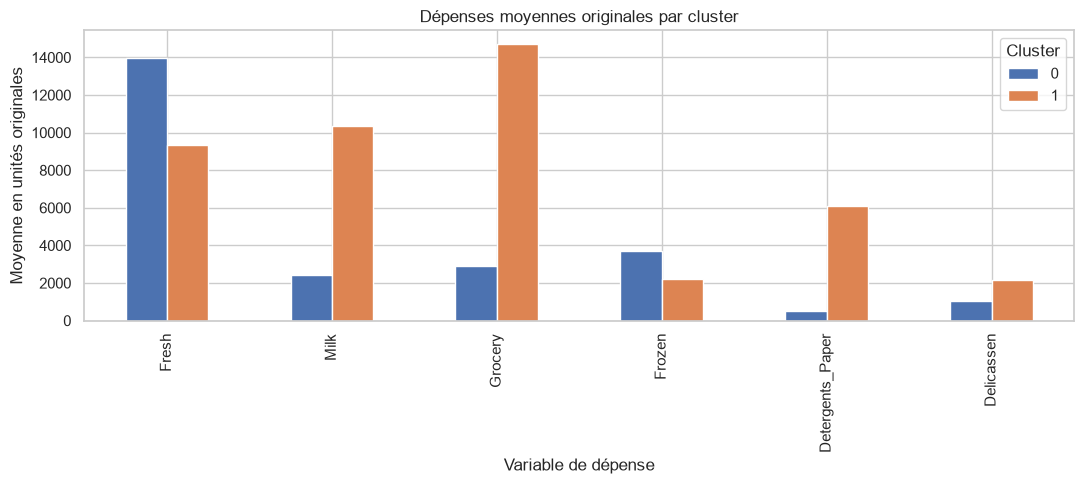

In [8]:
relative_profile = means.div(raw[FEATURES].mean(), axis=1)
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(relative_profile, annot=True, fmt='.2f', cmap='YlGnBu', center=1, ax=ax)
ax.set(title='Profils de dépenses par cluster', xlabel='Variable de dépense', ylabel='Cluster',)
ax.collections[0].colorbar.set_label('Moyenne du cluster / moyenne globale')
fig.tight_layout(); fig.savefig(figures_dir / '11_kmeans_cluster_profiles_heatmap.png', dpi=180, bbox_inches='tight'); plt.show(); plt.close(fig)
fig, ax = plt.subplots(figsize=(11, 5))
means.T.plot(kind='bar', ax=ax)
ax.set(title='Dépenses moyennes originales par cluster', xlabel='Variable de dépense', ylabel='Moyenne en unités originales'); ax.legend(title='Cluster')
fig.tight_layout(); fig.savefig(figures_dir / '12_kmeans_cluster_means.png', dpi=180, bbox_inches='tight'); plt.show(); plt.close(fig)

## 8. Projection PCA pour visualiser les labels

La PCA réduit temporairement les six dimensions préparées à deux axes pour produire une figure. K-Means n'est pas réentraîné sur PC1 et PC2 : cette projection peut masquer une partie de l'information.

Variance expliquée par PC1 : 44.08%
Variance expliquée par PC2 : 27.19%
Variance expliquée cumulée : 71.27%


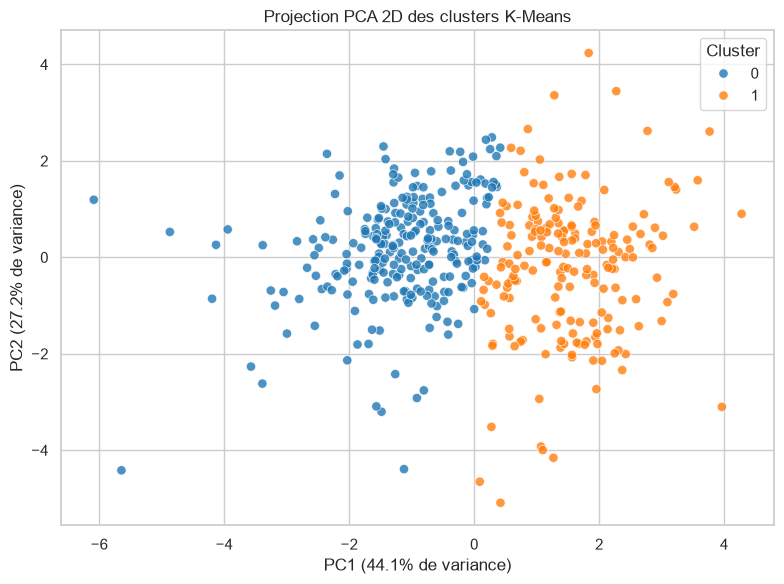

In [9]:
pca = PCA(n_components=2, random_state=42)
coordinates = pca.fit_transform(X)
pca_df = pd.DataFrame(coordinates, index=X.index, columns=['PC1', 'PC2'])
pca_df['cluster'] = labels
variance = pca.explained_variance_ratio_ * 100
print(f'Variance expliquée par PC1 : {variance[0]:.2f}%')
print(f'Variance expliquée par PC2 : {variance[1]:.2f}%')
print(f'Variance expliquée cumulée : {variance.sum():.2f}%')
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='cluster', palette='tab10', s=45, alpha=.8, ax=ax)
ax.set(title='Projection PCA 2D des clusters K-Means', xlabel=f'PC1 ({variance[0]:.1f}% de variance)', ylabel=f'PC2 ({variance[1]:.1f}% de variance)')
ax.legend(title='Cluster')
fig.tight_layout(); fig.savefig(figures_dir / '13_kmeans_pca_projection.png', dpi=180, bbox_inches='tight'); plt.show(); plt.close(fig)
pca_df.to_csv(tables_dir / 'kmeans_pca_coordinates.csv', index_label='customer_index')

## 9. Validation finale et conclusion

Les assertions suivantes vérifient que chaque client a exactement un label, que les effectifs totalisent 440 et que le modèle est reproductible avec `random_state=42`.

In [10]:
assert len(labels) == EXPECTED_ROWS
assert labels.notna().all() and labels.nunique() == selected_k
assert np.isfinite(labels.to_numpy()).all()
assert int(counts.sum()) == EXPECTED_ROWS
assert final_model.cluster_centers_.shape == (selected_k, len(FEATURES))
repeat_model = KMeans(n_clusters=selected_k, init='k-means++', n_init=20, random_state=42).fit(X)
assert np.array_equal(final_model.labels_, repeat_model.labels_)
print('VALIDATION : OK')
print(f'{EXPECTED_ROWS} observations affectées, {selected_k} clusters, aucun label manquant, centroïdes de dimension {len(FEATURES)}.')
print('Conclusion : la stratégie log1p + StandardScaler et le K provisoire ci-dessus sont prêts pour une analyse K-Means. Aucune CAH ni DBSCAN n’a été exécutée.')

VALIDATION : OK
440 observations affectées, 2 clusters, aucun label manquant, centroïdes de dimension 6.
Conclusion : la stratégie log1p + StandardScaler et le K provisoire ci-dessus sont prêts pour une analyse K-Means. Aucune CAH ni DBSCAN n’a été exécutée.
